## Session 2 : Language Processing Pipeline in Spacy (Spacy pipeline)
**pipeline comes after Tokenizer**

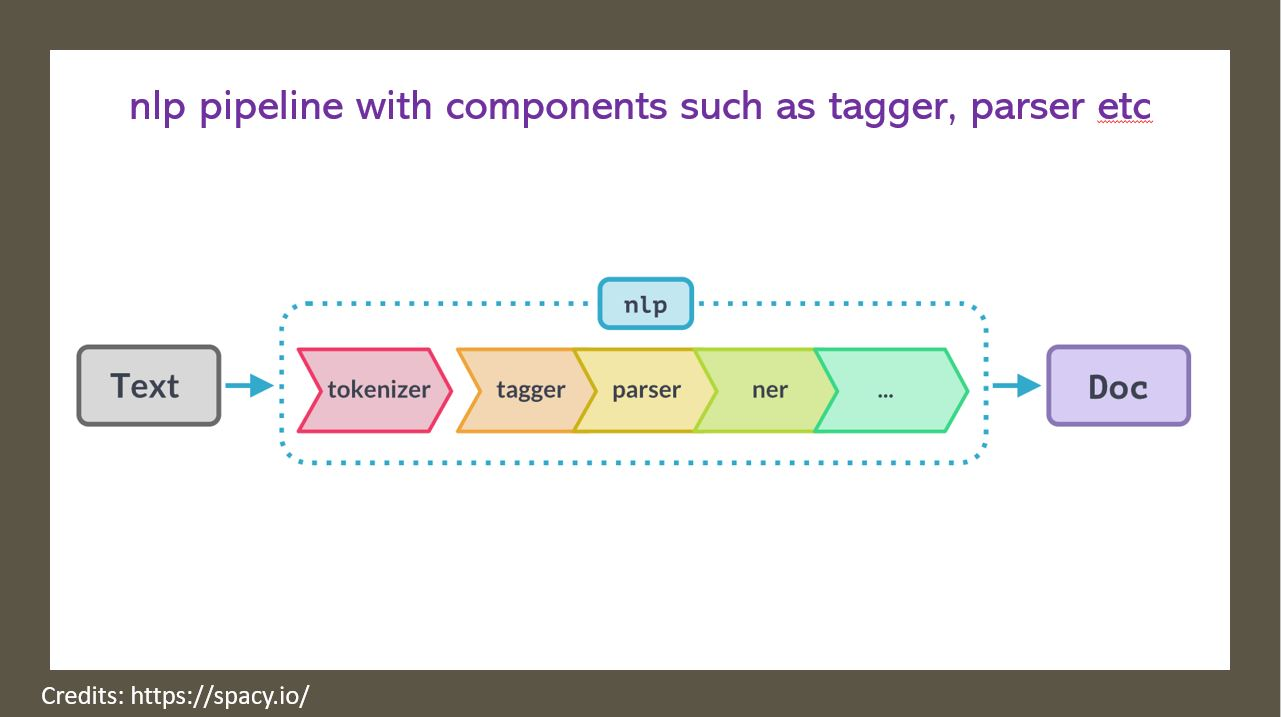

In [1]:
from IPython import display
display.Image("/media/elham/Learning/NLP/NLP/images/spacy_pipeline.jpg", width=500)

In [ ]:
# Small model for the English language
#!python -m spacy download en_core_web_sm

In [3]:
import spacy
# Check the small English model downloaded correctly
# Create an nlp Object
nlp = spacy.load("en_core_web_sm") # pretrain pipeline for English language

In [6]:
nlp.pipeline

[('tok2vec', <spacy.pipeline.tok2vec.Tok2Vec at 0x7fc78be70460>),
 ('tagger', <spacy.pipeline.tagger.Tagger at 0x7fc78be706a0>),
 ('parser', <spacy.pipeline.dep_parser.DependencyParser at 0x7fc78c139c80>),
 ('attribute_ruler',
  <spacy.pipeline.attributeruler.AttributeRuler at 0x7fc78b1c7fc0>),
 ('lemmatizer',
  <spacy.lang.en.lemmatizer.EnglishLemmatizer at 0x7fc78b1cc700>),
 ('ner', <spacy.pipeline.ner.EntityRecognizer at 0x7fc78c139ba0>)]

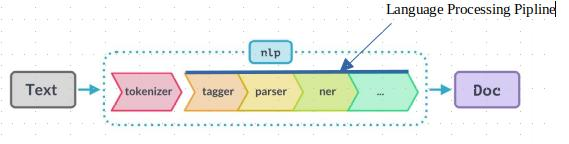

In [26]:
from IPython import display
display.Image("./spacy_pipeline2.jpg", width=500)

In [7]:
with open("wiki2.txt") as f:
    text = f.read()

print(text)

The United States of America (U.S.A. or USA), commonly known as the United States (U.S. or US) or America, is a country primarily located in North America.
It consists of 50 states, a federal district, five major unincorporated territories, 326 Indian reservations, and some minor possessions.[j]
At 3.8 million square miles (9.8 million square kilometers), it is the world's third- or fourth-largest country by total area.[d] The United States shares significant land borders with Canada to the north and Mexico to the south, as well as limited maritime borders with the Bahamas, Cuba, and Russia.[22] With a population of more than 331 million people, it is the third most populous country in the world.
The national capital is Washington, D.C., and the most populous city is New York.


Paleo-Indians migrated from Siberia to the North American mainland at least 12,000 years ago, and European colonization began in the 16th century.
The United States emerged from the thirteen British colonies es

In [8]:
doc = nlp(text)  #Creating a Doc Container
for sent in doc.sents:
    print(sent)

The United States of America (U.S.A. or USA), commonly known as the United States (U.S. or US) or America, is a country primarily located in North America.

It consists of 50 states, a federal district, five major unincorporated territories, 326 Indian reservations, and some minor possessions.[j]
At 3.8 million square miles (9.8 million square kilometers), it is the world's third- or fourth-largest country by total area.[d]
The United States shares significant land borders with Canada to the north and Mexico to the south, as well as limited maritime borders with the Bahamas, Cuba, and Russia.[22]
With a population of more than 331 million people, it is the third most populous country in the world.

The national capital is Washington, D.C., and the most populous city is New York.



Paleo-Indians migrated from Siberia to the North American mainland at least 12,000 years ago, and European colonization began in the 16th century.

The United States emerged from the thirteen British colonie

In [9]:
# Larger models are better at sentence detection. The model you are using,en_core_web_sm, is a small model
sents = list(doc.sents)
print(f"first sentence is : {sents[0]}")
print("*" * 10)
print(f"second sentence is : {sents[1]}")

first sentence is : The United States of America (U.S.A. or USA), commonly known as the United States (U.S. or US) or America, is a country primarily located in North America.

**********
second sentence is : It consists of 50 states, a federal district, five major unincorporated territories, 326 Indian reservations, and some minor possessions.[j]
At 3.8 million square miles (9.8 million square kilometers), it is the world's third- or fourth-largest country by total area.[d]


## Token Attributes
such as:
- .text
- .head
- .left_edge
- .right_edge
- .ent_type_
- .iob_
- .lemma_
- .morph
- .pos_
- .dep_
- .lang_

In [11]:
sent2 = sents[1]
token1 = sent2[1]  # Each token has a bunch of metadata (attributes)
print(token1)      # Token Object

consists


In [12]:
token1.text    # Extract text from token object

'consists'

In [13]:
token1.head  # The syntactic parent, or “governor”, of this token.

consists

In [14]:
print(f"second sentence is : {sent2}")
print("*" * 20)
print(f"left edge is : {token1.left_edge}")     #The leftmost token of this token’s syntactic descendants. 
print(f"right edge is : {token1.right_edge}")   #The rightmost token of this token’s syntactic descendants

second sentence is : It consists of 50 states, a federal district, five major unincorporated territories, 326 Indian reservations, and some minor possessions.[j]
At 3.8 million square miles (9.8 million square kilometers), it is the world's third- or fourth-largest country by total area.[d]
********************
left edge is : It
right edge is : ]


In [15]:
token23 = sent2[23]
print(f"token is : {token23.text}")
print(f"left edge is : {token23.left_edge}")
print(f"right edge is : {token23.right_edge}")

token is : ]
left edge is : ]
right edge is : 



In [16]:
print(f"Entity code : {token23.ent_type} and Entity type is {token23.ent_type_}")

Entity code : 0 and Entity type is 


***Note: IOB code of named entity tag.***
- **B** (Beginning): The token is the beginning of an entity.
- **I** (Inside): The token is the beginning of an entity and follows another token with a B or I tag of the same entity.
- **O** (Outside): The token is not part of any entity.

In [18]:
print(f"second sentence : {sent2}")

for token in sent2:
    print(f"token is : {token.text}, IOB code is : {token.ent_iob_}, lemmatization : {token.lemma_}, part of speech : {token.pos_}, dependency : {token.dep_}")
    print("*" * 30)

second sentence : It consists of 50 states, a federal district, five major unincorporated territories, 326 Indian reservations, and some minor possessions.[j]
At 3.8 million square miles (9.8 million square kilometers), it is the world's third- or fourth-largest country by total area.[d]
token is : It, IOB code is : O, lemmatization : it, part of speech : PRON, dependency : nsubj
******************************
token is : consists, IOB code is : O, lemmatization : consist, part of speech : VERB, dependency : ROOT
******************************
token is : of, IOB code is : O, lemmatization : of, part of speech : ADP, dependency : prep
******************************
token is : 50, IOB code is : B, lemmatization : 50, part of speech : NUM, dependency : nummod
******************************
token is : states, IOB code is : O, lemmatization : state, part of speech : NOUN, dependency : pobj
******************************
token is : ,, IOB code is : O, lemmatization : ,, part of speech : PUNCT

In [19]:
print(f"second sentence : {sent2}")
print("*" * 30)
for token in sent2:
    print(f"token is : {token.text}, morphology is : {token.morph}")

second sentence : It consists of 50 states, a federal district, five major unincorporated territories, 326 Indian reservations, and some minor possessions.[j]
At 3.8 million square miles (9.8 million square kilometers), it is the world's third- or fourth-largest country by total area.[d]
******************************
token is : It, morphology is : Case=Nom|Gender=Neut|Number=Sing|Person=3|PronType=Prs
token is : consists, morphology is : Number=Sing|Person=3|Tense=Pres|VerbForm=Fin
token is : of, morphology is : 
token is : 50, morphology is : NumType=Card
token is : states, morphology is : Number=Plur
token is : ,, morphology is : PunctType=Comm
token is : a, morphology is : Definite=Ind|PronType=Art
token is : federal, morphology is : Degree=Pos
token is : district, morphology is : Number=Sing
token is : ,, morphology is : PunctType=Comm
token is : five, morphology is : NumType=Card
token is : major, morphology is : Degree=Pos
token is : unincorporated, morphology is : Degree=Pos
to

## display Part of Speech Tagging (POS)

In [20]:
from spacy import displacy


ex_text = "Tokenization is a process used in text analysis that divides text into individual words or word fragments."

doc_ex = nlp(ex_text)

print(f"sentence is : {ex_text}")
print("*" * 30)
for token in doc_ex:
    print(f"token is : {token.text}, part of speech : {token.pos_}, dependency : {token.dep_}")

displacy.render(doc_ex, style="dep")

sentence is : Tokenization is a process used in text analysis that divides text into individual words or word fragments.
******************************
token is : Tokenization, part of speech : NOUN, dependency : nsubj
token is : is, part of speech : AUX, dependency : ROOT
token is : a, part of speech : DET, dependency : det
token is : process, part of speech : NOUN, dependency : attr
token is : used, part of speech : VERB, dependency : acl
token is : in, part of speech : ADP, dependency : prep
token is : text, part of speech : NOUN, dependency : compound
token is : analysis, part of speech : NOUN, dependency : pobj
token is : that, part of speech : PRON, dependency : nsubj
token is : divides, part of speech : VERB, dependency : relcl
token is : text, part of speech : NOUN, dependency : dobj
token is : into, part of speech : ADP, dependency : prep
token is : individual, part of speech : ADJ, dependency : amod
token is : words, part of speech : NOUN, dependency : pobj
token is : or, par

## Named Entity Recognition

In [22]:
doc = nlp("Tesla Inc is going to acquire twitter for $45 billion")
for ent in doc.ents:
    print(ent.text, " | ", ent.label_, " | ", spacy.explain(ent.label_))

Tesla Inc  |  ORG  |  Companies, agencies, institutions, etc.
$45 billion  |  MONEY  |  Monetary values, including unit


In [ ]:
# This small model does not have word vectors so it makes some mistakes :(   token the American Civil War is an Event, not ORG
for ent in doc.ents:
    print(f"token is : {ent.text}, entity is : {ent.label_} ")

## Word Vectors and spaCy
***Note: The English small model does not have word vectors or word embeddings saved however the medium  model does.***

Initial methods for creating word vectors in a pipeline take all words in a corpus and convert them into a single, unique number. These words are then stored in a dictionary that would look like this: {“the”: 1, “a”, 2} etc. This is known as a *bag of words*. This approach to representing words numerically, however, only allow a computer to understand words numerically to identify unique words. It does not, however, allow a computer to understand meaning. Hence, for text understanding or trying to get a computer system to be able to understand how a word functions within the sentence and how relates to other words in general that does not really work for us.

***List of all supported Named Entities***
- PERSON:      People, including fictional.
- NORP:        Nationalities or religious or political groups.
- FAC:         Buildings, airports, highways, bridges, etc.
- ORG:         Companies, agencies, institutions, etc.
- GPE:         Countries, cities, states.
- LOC:         Non-GPE locations, mountain ranges, bodies of water.
- PRODUCT:     Objects, vehicles, foods, etc. (Not services.)
- EVENT:       Named hurricanes, battles, wars, sports events, etc.
- WORK_OF_ART: Titles of books, songs, etc.
- LAW:         Named documents made into laws.
- LANGUAGE:    Any named language.
- DATE:        Absolute or relative dates or periods.
- TIME:        Times smaller than a day.
- PERCENT:     Percentage, including ”%“.
- MONEY:       Monetary values, including unit.
- QUANTITY:    Measurements, as of weight or distance.
- ORDINAL:     “first”, “second”, etc.
- CARDINAL:    Numerals that do not fall under another type.